In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
df = pd.read_csv("../data/cleaned_data.csv")

df.head()

,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show,ScheduledDate,AppointmentDate,WaitingDays,ScheduledDayOfWeek,AppointmentDayOfWeek,AppointmentMonth
0,2.987250e+13,5642903,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,0,4,4,4
1,5.589978e+14,5642503,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,0,4,4,4
2,4.262962e+12,5642549,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,0,4,4,4
3,8.679512e+11,5642828,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,0,4,4,4
4,8.841186e+12,5642494,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,2016-04-29 00:00:00+00:00,2016-04-29 00:00:00+00:00,0,4,4,4


In [4]:
print("Dataset shape:", df.shape)
df.info()

Dataset shape: (110521, 20)
<class 'pandas.DataFrame'>
RangeIndex: 110521 entries, 0 to 110520
Data columns (total 20 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   PatientId             110521 non-null  float64
 1   AppointmentID         110521 non-null  int64  
 2   Gender                110521 non-null  str    
 3   ScheduledDay          110521 non-null  str    
 4   AppointmentDay        110521 non-null  str    
 5   Age                   110521 non-null  int64  
 6   Neighbourhood         110521 non-null  str    
 7   Scholarship           110521 non-null  int64  
 8   Hipertension          110521 non-null  int64  
 9   Diabetes              110521 non-null  int64  
 10  Alcoholism            110521 non-null  int64  
 11  Handcap               110521 non-null  int64  
 12  SMS_received          110521 non-null  int64  
 13  No-show               110521 non-null  str    
 14  ScheduledDate         110521 non-nu

In [5]:
# Count appointment outcomes
no_show_counts = df["No-show"].value_counts()

print(no_show_counts)

No-show
No     88207
Yes    22314
Name: count, dtype: int64


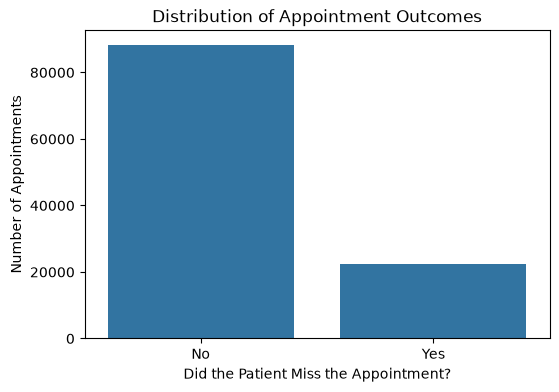

In [6]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="No-show")

plt.title("Distribution of Appointment Outcomes")
plt.xlabel("Did the Patient Miss the Appointment?")
plt.ylabel("Number of Appointments")

plt.show()

In [7]:
df["Age"].describe()

count    110521.000000
mean         37.089386
std          23.109885
min           0.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

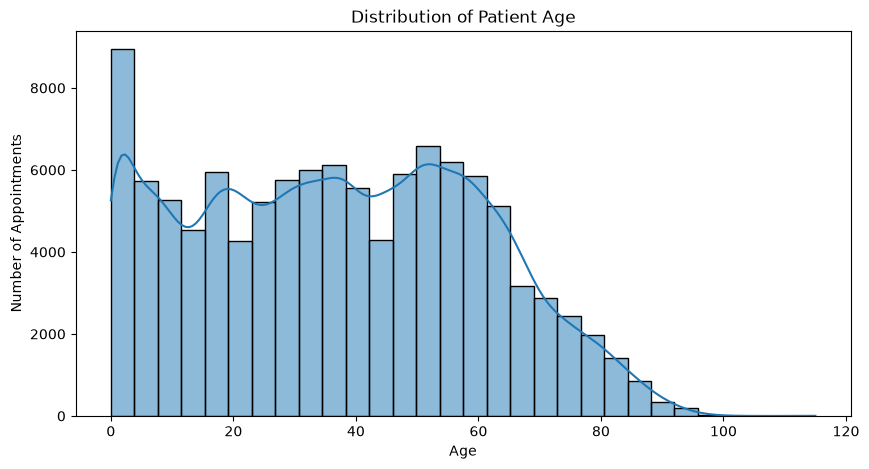

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="Age", bins=30, kde=True)

plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Number of Appointments")

plt.show()

Compare age by appointment outcome

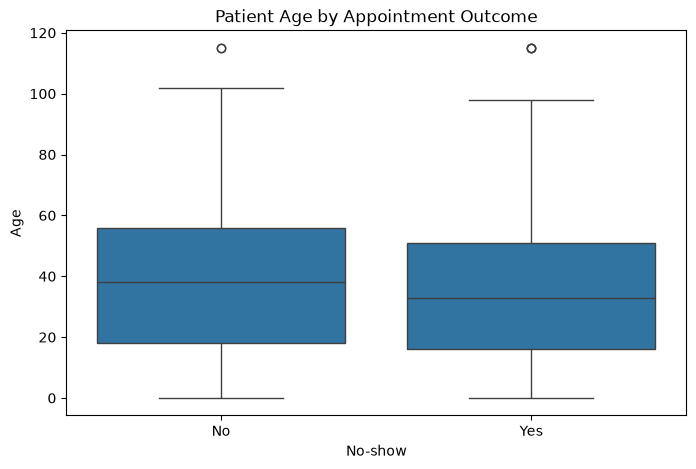

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="No-show", y="Age")

plt.title("Patient Age by Appointment Outcome")
plt.xlabel("No-show")
plt.ylabel("Age")

plt.show()

In [10]:
df.groupby("No-show")["Age"].agg(["count", "mean", "median", "min", "max"]).round(2)

,count,mean,median,min,max
No-show,,,,,
No,88207,37.79,38.0,0,115
Yes,22314,34.32,33.0,0,115


Patients who missed their appointments were generally younger than those who attended:

Gender vs. No-show

In [11]:
# Count appointments by gender and outcome
pd.crosstab(
    df["Gender"],
    df["No-show"],
    normalize="index"
).mul(100).round(2)

No-show,No,Yes
Gender,,
F,79.69,20.31
M,80.04,19.96


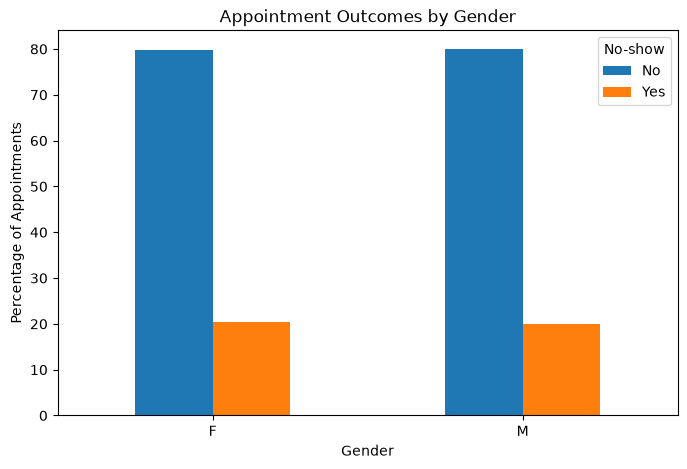

In [12]:
no_show_by_gender = (
    pd.crosstab(
        df["Gender"],
        df["No-show"],
        normalize="index"
    )
    .mul(100)
)

no_show_by_gender.plot(kind="bar", figsize=(8, 5))

plt.title("Appointment Outcomes by Gender")
plt.xlabel("Gender")
plt.ylabel("Percentage of Appointments")
plt.legend(title="No-show")

plt.xticks(rotation=0)
plt.show()

Gender does not appear to have a strong relationship with appointment attendance in this dataset.

Analyze waiting time

In [13]:
df.groupby("No-show")["WaitingDays"].agg(
    ["count", "mean", "median", "min", "max"]
).round(2)

,count,mean,median,min,max
No-show,,,,,
No,88207,8.75,2.0,0,179
Yes,22314,15.84,11.0,0,179


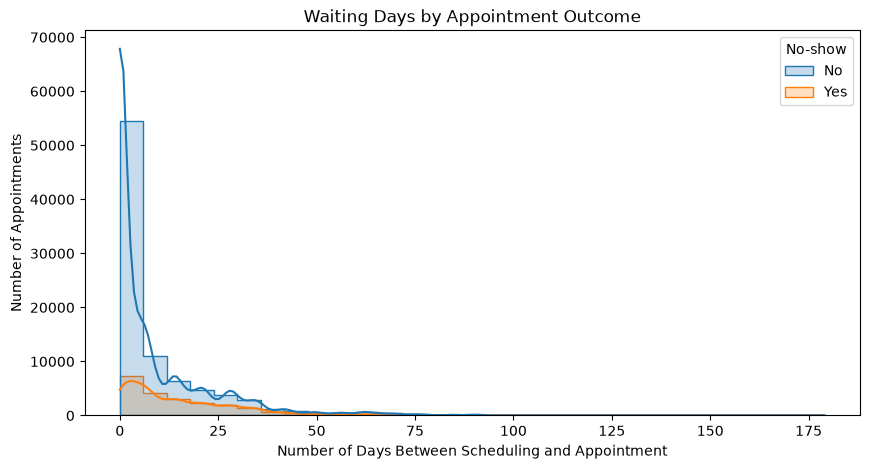

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="WaitingDays",
    hue="No-show",
    bins=30,
    kde=True,
    element="step"
)

plt.title("Waiting Days by Appointment Outcome")
plt.xlabel("Number of Days Between Scheduling and Appointment")
plt.ylabel("Number of Appointments")

plt.show()

Finding: Waiting time and appointment attendance
Patients who missed their appointments had substantially longer waiting times than those who attended. The average waiting time for no-show appointments was 15.84 days, compared with 8.75 days for appointments where patients attended. The median waiting time showed an even clearer difference: 11 days for no-show appointments versus 2 days for attended appointments. This suggests that longer waiting periods may be associated with a higher likelihood of missing an appointment.

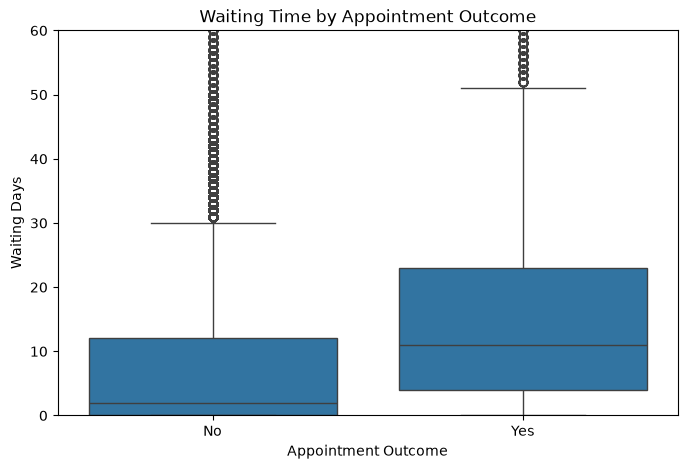

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="No-show",
    y="WaitingDays"
)

plt.title("Waiting Time by Appointment Outcome")
plt.xlabel("Appointment Outcome")
plt.ylabel("Waiting Days")

plt.ylim(0, 60)
plt.show()

#### Analyze SMS reminders

In [16]:
sms_no_show = (
    pd.crosstab(
        df["SMS_received"],
        df["No-show"],
        normalize="index"
    )
    .mul(100)
    .round(2)
)

sms_no_show

No-show,No,Yes
SMS_received,,
0,83.30,16.70
1,72.43,27.57


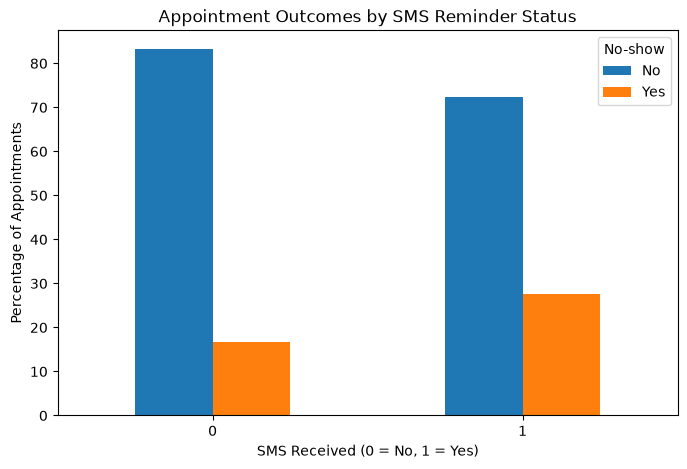

In [17]:
sms_no_show.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Appointment Outcomes by SMS Reminder Status")
plt.xlabel("SMS Received (0 = No, 1 = Yes)")
plt.ylabel("Percentage of Appointments")
plt.legend(title="No-show")

plt.xticks(rotation=0)
plt.show()

Finding: SMS reminders and appointment attendance
Patients who received an SMS reminder had a higher no-show rate (27.57%) than those who did not receive an SMS reminder (16.70%). However, this result does not mean that SMS reminders cause patients to miss appointments. Other factors, such as appointment waiting time, may influence both whether a patient receives an SMS and whether they attend their appointment. Further analysis would be needed to understand this relationship.

### analysis — appointment day

In [18]:
# Calculate no-show rates by day of the week
day_no_show = (
    df.groupby("AppointmentDayOfWeek")["No-show"]
    .value_counts(normalize=True)
    .unstack()
    .mul(100)
    .round(2)
)

# Rename the index for readability
day_names = {
    0: "Monday",
    1: "Tuesday",
    2: "Wednesday",
    3: "Thursday",
    4: "Friday",
    5: "Saturday",
    6: "Sunday"
}

day_no_show.index = day_no_show.index.map(day_names)

day_no_show

No-show,No,Yes
AppointmentDayOfWeek,,
Monday,79.36,20.64
Tuesday,79.91,20.09
Wednesday,80.31,19.69
Thursday,80.65,19.35
Friday,78.77,21.23
Saturday,76.92,23.08


Finding: Appointment day and no-shows
No-show rates were relatively consistent across most days of the week, ranging from 19.35% to 21.23% on weekdays. Saturday had the highest no-show rate at 23.08%. Although the differences are relatively small, the day of the appointment may still contribute useful information when combined with other features in the machine learning model.

#### Exploratory Data Analysis Summary
The exploratory analysis identified several patterns related to appointment no-shows. Patients who missed appointments were generally younger than those who attended. Gender showed very little difference in no-show rates. Waiting time showed a stronger relationship with appointment attendance, with no-show patients waiting substantially longer on average. Patients who received SMS reminders had a higher observed no-show rate, although this relationship should not be interpreted as causal because other factors may influence both SMS reminders and appointment attendance. Finally, no-show rates were relatively consistent across appointment days, with Saturday showing a slightly higher rate.